# AI Model Experiment & Evaluation
**Sentiment Analysis Ulasan Pelanggan: Model Klasik (Scikit-learn) vs LLM API (Gemini)**

Penulis: Muhammad Ariel Shakaramiro, AI Engineering Bootcamp

Notebook ini membandingkan dua pendekatan AI untuk mengklasifikasikan sentimen ulasan pelanggan e-commerce (`positif` / `negatif`):
1. **Model klasik Machine Learning**: TF-IDF + Logistic Regression (Scikit-learn), dilatih sendiri.
2. **LLM API**: Gemini via `google-genai`, dengan prompting zero-shot dan few-shot tanpa training.

Kedua pendekatan dievaluasi pada **test set yang sama** dengan metrik Accuracy, Precision, Recall, F1-Score, dan confusion matrix.

> **Cara menjalankan bagian Gemini:** isi `GEMINI_API_KEY` di file `.env` (salin dari `.env.example`). Hasil panggilan API disimpan ke `results/llm_cache.json`, sehingga notebook tetap bisa dijalankan ulang **tanpa API key** dan tanpa biaya tambahan, memakai prediksi yang sudah tersimpan.

## 1. Problem Statement

**Objective.** Tim produk e-commerce ingin fitur otomatis yang mengklasifikasikan sentimen ulasan pelanggan pada halaman produk. Eksperimen ini menjawab pertanyaan: *pendekatan mana (model klasik yang dilatih sendiri atau LLM API berbasis prompting) yang sebaiknya dikembangkan ke produksi*, berdasarkan performa, effort implementasi, kecepatan, dan biaya.

**Target/label.** Klasifikasi biner pada kolom `sentiment`:
- `positif`: ulasan yang menyatakan kepuasan (kualitas, pengiriman, pelayanan baik).
- `negatif`: ulasan yang menyatakan kekecewaan atau keluhan.

Input model hanya kolom `review_text`. Kolom `product_name` tidak dipakai sebagai fitur karena sentimen ditentukan oleh isi ulasan, bukan nama produk.

**Batasan & asumsi.**
- Dataset yang digunakan adalah dataset resmi assignment (200 baris, berbahasa Indonesia) dan tidak diubah.
- Label pada dataset dianggap *ground truth* yang benar.
- Hanya dua kelas; tidak ada kelas `netral` atau ulasan campuran (*mixed*). Ulasan semacam itu di dunia nyata berada di luar cakupan eksperimen ini.
- Training deep learning dari nol tidak termasuk cakupan.
- Biaya API diestimasi dari jumlah token aktual × harga publik Gemini API saat eksperimen. Harga dapat berubah.

## 2. Import Library & Load Dataset

In [1]:
import os
import json
import time
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GroupShuffleSplit, GroupKFold, cross_validate
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
)
from google import genai
from google.genai import types

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Root project terdeteksi otomatis, baik notebook dijalankan dari root maupun dari folder notebook/
ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
DATA_PATH = ROOT / "data" / "customer_reviews_sentiment.csv"
RESULTS_DIR = ROOT / "results"
DOCS_DIR = ROOT / "documentation"
RESULTS_DIR.mkdir(exist_ok=True)
DOCS_DIR.mkdir(exist_ok=True)

# Muat .env (jika ada) agar GEMINI_API_KEY tidak perlu di-hardcode
try:
    from dotenv import load_dotenv
    load_dotenv(ROOT / ".env", override=True)  # override: perubahan .env langsung terbaca saat Run All ulang
except ImportError:
    pass

TEXT_COL, LABEL_COL = "review_text", "sentiment"
LABELS = ["negatif", "positif"]

df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
df.head()

Shape: (200, 4)


,review_id,product_name,review_text,sentiment
0,1,Kemeja Flanel,Pelayanan lambat dan tidak responsif saat dikomplain.,negatif
1,2,Case HP,"Puas banget belanja disini, proses cepat dan barang aman.",positif
2,3,Rice Cooker,"Terima kasih seller, barangnya awet dan sesuai deskripsi.",positif
3,4,Case HP,Warna produk berbeda jauh dari foto di listing.,negatif
4,5,Headset Bluetooth,"Terima kasih seller, barangnya awet dan sesuai deskripsi.",positif


### 2.1 Eksplorasi singkat dataset

In [2]:
print("Missing values per kolom:\n", df.isna().sum(), "\n")
print("Distribusi label:")
print(df[LABEL_COL].value_counts().to_frame("jumlah").assign(proporsi=lambda d: (d["jumlah"] / len(df)).round(3)), "\n")

n_unique = df[TEXT_COL].nunique()
print(f"Jumlah baris            : {len(df)}")
print(f"Jumlah teks ulasan unik : {n_unique}")
print(f"Baris duplikat (teks)   : {len(df) - n_unique}")

conflict = df.groupby(TEXT_COL)[LABEL_COL].nunique()
print(f"Teks dengan label bertentangan: {(conflict > 1).sum()}")
df["n_words"] = df[TEXT_COL].str.split().str.len()
print(f"Panjang ulasan (kata): min={df.n_words.min()}, median={df.n_words.median():.0f}, max={df.n_words.max()}")

Missing values per kolom:
 review_id       0
product_name    0
review_text     0
sentiment       0
dtype: int64 

Distribusi label:
           jumlah  proporsi
sentiment                  
positif       110      0.55
negatif        90      0.45 

Jumlah baris            : 200
Jumlah teks ulasan unik : 40
Baris duplikat (teks)   : 160
Teks dengan label bertentangan: 0
Panjang ulasan (kata): min=6, median=8, max=11


**Temuan penting:** dari 200 baris hanya ada **40 teks ulasan unik** (20 positif, 20 negatif). Setiap teks muncul 1–12 kali dengan nama produk berbeda. Label konsisten (tidak ada teks yang sama dengan label berbeda) dan tidak ada missing value. Distribusi label cukup seimbang (55% positif, 45% negatif), sehingga accuracy masih bermakna, tetapi tetap dilengkapi precision/recall/F1 per kelas.

Implikasinya: split acak per baris hampir pasti menaruh teks yang **sama persis** di train dan test (*data leakage*). Hal ini diukur di Section 3 dan dikoreksi dengan eksperimen pelengkap (Section 6.4).

## 3. Menyiapkan Train/Test Split

Split utama mengikuti starter notebook (80/20, `stratify`, `random_state=42`). **Test set yang sama (`X_test`, `y_test`) dipakai untuk kedua pendekatan.**

In [3]:
X = df[TEXT_COL]
y = df[LABEL_COL]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

print("Train size:", len(X_train))
print("Test size :", len(X_test))
print("\nDistribusi label test set:\n", y_test.value_counts())

# Simpan indeks test set agar dapat diaudit & dipakai ulang
pd.DataFrame({"row_index": X_test.index, TEXT_COL: X_test.values, LABEL_COL: y_test.values}) \
  .to_csv(RESULTS_DIR / "test_set.csv", index=False)

Train size: 160
Test size : 40

Distribusi label test set:
 sentiment
positif    22
negatif    18
Name: count, dtype: int64


### 3.1 Cek data leakage antara train dan test

In [4]:
train_texts = set(X_train)
leaked = X_test.isin(train_texts)
print(f"Baris test yang teksnya juga ada di train : {leaked.sum()} / {len(X_test)} ({leaked.mean():.0%})")
print(f"Teks unik di test set                     : {X_test.nunique()}")
print(f"Teks unik test yang TIDAK pernah dilihat  : {X_test[~leaked].nunique()}")

Baris test yang teksnya juga ada di train : 39 / 40 (98%)
Teks unik di test set                     : 26
Teks unik test yang TIDAK pernah dilihat  : 1


Hampir seluruh test set berisi kalimat yang sudah dilihat model klasik saat training. Skor model klasik pada split ini lebih mencerminkan kemampuan **menghafal** daripada **generalisasi** ke ulasan baru. Sebaliknya, LLM tidak dilatih pada data ini, sehingga skornya tidak terpengaruh leakage.

Agar perbandingan tetap adil sesuai brief, split utama ini **tetap dipakai sebagai perbandingan resmi**. Section 6.4 menambahkan evaluasi *leakage-free* (split per teks unik / `GroupShuffleSplit`) untuk mengukur kemampuan generalisasi model klasik yang sebenarnya.

### 3.2 Split pelengkap *leakage-free* (dipakai di Section 6.4)

Split kedua dibuat **berdasarkan teks unik** (`GroupShuffleSplit`, group = `review_text`), sehingga kalimat di test set dijamin tidak pernah muncul di train. Split ini didefinisikan sekarang supaya contoh few-shot LLM (Section 5.2) bisa dipastikan tidak bocor ke test set mana pun.

In [5]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
tr_idx, te_idx = next(gss.split(X, y, groups=X))
Xg_tr, Xg_te, yg_tr, yg_te = X.iloc[tr_idx], X.iloc[te_idx], y.iloc[tr_idx], y.iloc[te_idx]
print(f"Train: {len(Xg_tr)} baris ({Xg_tr.nunique()} teks unik) | Test: {len(Xg_te)} baris ({Xg_te.nunique()} teks unik)")
print("Overlap teks train-test:", len(set(Xg_tr) & set(Xg_te)))
print("Distribusi label test leakage-free:", yg_te.value_counts().to_dict())

Train: 159 baris (32 teks unik) | Test: 41 baris (8 teks unik)
Overlap teks train-test: 0
Distribusi label test leakage-free: {'positif': 27, 'negatif': 14}


## 4. Pendekatan 1 — Model Klasik (Scikit-learn)

### 4.1 Preprocessing & Feature Extraction

- **TF-IDF** dengan unigram + bigram (`ngram_range=(1,2)`) agar frasa seperti *"tidak sesuai"* dan *"tidak mengecewakan"* tertangkap sebagai satu fitur. Ini penting karena negasi mengubah makna sentimen.
- `lowercase=True` (default) dan `sublinear_tf=True` untuk meredam kata yang sering muncul.
- **Tidak menghapus stopword**: stopword bahasa Indonesia seperti *"tidak"* dan *"belum"* justru membawa sinyal sentimen.

In [6]:
vectorizer = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, lowercase=True)

t0 = time.perf_counter()
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)
vec_time = time.perf_counter() - t0

print("Ukuran vocabulary (fitur):", len(vectorizer.vocabulary_))
print("Shape X_train_vec:", X_train_vec.shape)

Ukuran vocabulary (fitur): 384
Shape X_train_vec: (160, 384)


### 4.2 Training Model

**Logistic Regression** dipilih karena model linear ini kuat untuk teks berdimensi tinggi dan sparse, cepat dilatih, dan **interpretable** (bobot per kata/frasa bisa dibaca). Sebagai pembanding, **DummyClassifier** (selalu menebak kelas mayoritas) dipakai sebagai baseline minimum.

In [7]:
clf = LogisticRegression(max_iter=1000, random_state=SEED)

t0 = time.perf_counter()
clf.fit(X_train_vec, y_train)
train_time = time.perf_counter() - t0

baseline = DummyClassifier(strategy="most_frequent").fit(X_train_vec, y_train)

print(f"Waktu vectorize : {vec_time*1000:.1f} ms")
print(f"Waktu training  : {train_time*1000:.1f} ms")

Waktu vectorize : 8.6 ms
Waktu training  : 8.1 ms


Kata/frasa dengan bobot paling kuat (interpretasi model):

In [8]:
feat = np.array(vectorizer.get_feature_names_out())
coef = clf.coef_[0]  # bobot positif -> condong ke kelas 'positif'
top = pd.DataFrame({
    "paling_negatif": feat[np.argsort(coef)[:10]],
    "bobot_neg": np.sort(coef)[:10].round(3),
    "paling_positif": feat[np.argsort(coef)[::-1][:10]],
    "bobot_pos": np.sort(coef)[::-1][:10].round(3),
})
top

,paling_negatif,bobot_neg,paling_positif,bobot_pos
0,lambat,-0.840,cepat,1.092
1,jauh dari,-0.740,rapi,0.678
2,jauh,-0.740,ada,0.637
3,sekali sudah,-0.690,puas,0.586
4,sudah,-0.642,recommended,0.568
5,lambat dan,-0.629,cepat dari,0.562
6,tidak,-0.601,lebih cepat,0.562
7,sekali,-0.593,lebih,0.562
8,rusak,-0.570,pas tidak,0.542
9,tidak sesuai,-0.555,dipakai ukuran,0.542


### 4.3 Prediksi pada Test Set

In [9]:
t0 = time.perf_counter()
y_pred_classic = clf.predict(X_test_vec)
classic_infer_time = time.perf_counter() - t0
y_pred_baseline = baseline.predict(X_test_vec)

print(f"Waktu inferensi {len(X_test)} ulasan: {classic_infer_time*1000:.2f} ms "
      f"({classic_infer_time/len(X_test)*1000:.3f} ms/ulasan)")

Waktu inferensi 40 ulasan: 0.98 ms (0.025 ms/ulasan)


## 5. Pendekatan 2 — LLM API (Gemini)

### 5.1 Setup API

API key dibaca dari environment variable `GEMINI_API_KEY` (file `.env`), tidak di-hardcode. Model diatur lewat `GEMINI_MODEL`.

Model yang dipakai: **`gemini-3.1-flash-lite`**. `gemini-2.0-flash` dari starter sudah dihentikan Google (1 Juni 2026). Awalnya saya mencoba `gemini-3.8-flash`, tetapi kuota harian free tier-nya habis di tengah eksperimen, jadi seluruh prediksi diulang dengan `gemini-3.1-flash-lite` supaya semua hasil berasal dari satu model.

Setiap respons API disimpan di `results/llm_cache.json`. Kalau API key tidak ada, notebook memakai hasil tersimpan ini, jadi notebook tetap bisa dijalankan ulang (misalnya oleh mentor) tanpa memanggil API.

In [10]:
# Simpan API key di file .env, JANGAN hardcode langsung di notebook
API_KEY = os.environ.get("GEMINI_API_KEY")
GEMINI_MODEL = os.environ.get("GEMINI_MODEL", "gemini-3.1-flash-lite")

CACHE_PATH = RESULTS_DIR / "llm_cache.json"
cache = json.loads(CACHE_PATH.read_text(encoding="utf-8")) if CACHE_PATH.exists() else {}

client = genai.Client(api_key=API_KEY) if API_KEY else None

print("Model           :", GEMINI_MODEL)
print("API key         :", "ada" if API_KEY else "tidak ada -> memakai hasil tersimpan di cache")
print("Entri di cache  :", len(cache))

Model           : gemini-3.1-flash-lite
API key         : tidak ada -> memakai hasil tersimpan di cache
Entri di cache  : 64


### 5.2 Merancang Prompt

Dua strategi prompt diuji agar terlihat pengaruh desain prompt terhadap performa:

| Strategi | Isi prompt | Alasan |
|---|---|---|
| **Zero-shot** | System instruction berisi peran, definisi tiap label, dan aturan output | Baseline LLM murni tanpa contoh. Mengukur pemahaman bawaan model terhadap bahasa Indonesia. |
| **Few-shot** | Zero-shot + 4 contoh berlabel (2 positif, 2 negatif) | Contoh membantu model mengikuti format label dan gaya bahasa e-commerce Indonesia. Contoh diambil **hanya dari train set** dan dipastikan **tidak sama** dengan teks mana pun di test set utama maupun test set leakage-free, agar tidak terjadi leakage lewat prompt. |

**Desain output:** model diminta menjawab tepat satu label. Selain itu dipakai *structured output* (`response_mime_type="text/x.enum"`) yang **membatasi** jawaban hanya `positif`/`negatif`. Output tetap dinormalisasi (lowercase, strip, pencocokan kata) sebagai pengaman.

**Parameter yang dipakai:**

| Parameter | Nilai | Alasan |
|---|---|---|
| `temperature` | `0.0` | Klasifikasi adalah tugas deterministik: diinginkan jawaban paling probable dan **reproducible**, bukan variasi kreatif. Starter memakai 0.2; nilai 0 lebih tepat untuk evaluasi yang bisa diulang. |
| `thinking_level` | `LOW` | Tugas sederhana tidak butuh penalaran panjang. Thinking rendah menekan latensi dan token output (biaya). |
| `response_mime_type` + `response_schema` (enum) | `positif` / `negatif` | Menjamin output valid dan mudah diparsing. |
| `seed` | `42` | Membantu reproducibility. |

In [11]:
SYSTEM_INSTRUCTION = '''Anda adalah sistem klasifikasi sentimen untuk ulasan pelanggan e-commerce berbahasa Indonesia.
Tugas: tentukan sentimen ulasan sebagai salah satu label berikut.
- positif: pelanggan puas atau memuji produk, pengiriman, atau pelayanan.
- negatif: pelanggan kecewa, mengeluh, atau melaporkan masalah pada produk, pengiriman, atau pelayanan.
Perhatikan negasi (contoh: "tidak mengecewakan" bermakna positif).
Jawab HANYA dengan satu kata huruf kecil: positif atau negatif. Tanpa penjelasan.'''

# Few-shot: ambil contoh dari TRAIN set yang teksnya tidak muncul di test set utama
# maupun test set leakage-free, agar tidak ada kebocoran lewat prompt
test_texts = set(X_test) | set(Xg_te)
train_pool = (pd.DataFrame({TEXT_COL: X_train, LABEL_COL: y_train})
              .drop_duplicates(TEXT_COL)
              .loc[lambda d: ~d[TEXT_COL].isin(test_texts)])
few_shot_examples = pd.concat([
    train_pool[train_pool[LABEL_COL] == lab].sample(2, random_state=SEED) for lab in ["positif", "negatif"]
]).sample(frac=1, random_state=SEED)
print(f"Kandidat contoh few-shot (train, tidak ada di test): {len(train_pool)} teks unik")
display(few_shot_examples)

FEW_SHOT_BLOCK = "\n\n".join(f'Ulasan: "{r[TEXT_COL]}"\nSentimen: {r[LABEL_COL]}' for _, r in few_shot_examples.iterrows())

def build_prompt(review_text, mode="zero_shot"):
    if mode == "few_shot":
        return f'Berikut contoh klasifikasi:\n\n{FEW_SHOT_BLOCK}\n\nSekarang klasifikasikan ulasan berikut.\nUlasan: "{review_text}"\nSentimen:'
    return f'Ulasan: "{review_text}"\nSentimen:'

print("=== Contoh prompt few-shot ===")
print(build_prompt("<teks ulasan>", "few_shot"))

Kandidat contoh few-shot (train, tidak ada di test): 12 teks unik


,review_text,sentiment
130,"Terima kasih seller, barangnya awet dan sesuai deskripsi.",positif
199,"Pengalaman belanja terburuk, tidak akan order lagi disini.",negatif
169,"Respon cepat kalau ada pertanyaan, sangat membantu.",positif
13,"Barang yang datang tidak sesuai dengan foto, kecewa berat.",negatif


=== Contoh prompt few-shot ===
Berikut contoh klasifikasi:

Ulasan: "Terima kasih seller, barangnya awet dan sesuai deskripsi."
Sentimen: positif

Ulasan: "Pengalaman belanja terburuk, tidak akan order lagi disini."
Sentimen: negatif

Ulasan: "Respon cepat kalau ada pertanyaan, sangat membantu."
Sentimen: positif

Ulasan: "Barang yang datang tidak sesuai dengan foto, kecewa berat."
Sentimen: negatif

Sekarang klasifikasikan ulasan berikut.
Ulasan: "<teks ulasan>"
Sentimen:


In [12]:
TEMPERATURE = 0.0

def normalize_label(raw):
    # Normalisasi output LLM: lowercase, buang spasi/tanda baca, lalu cocokkan dengan label
    text = str(raw or "").strip().lower().strip(' ."\'')
    if text in LABELS:
        return text
    if "negatif" in text and "positif" not in text:
        return "negatif"
    if "positif" in text and "negatif" not in text:
        return "positif"
    return "invalid"

config = types.GenerateContentConfig(
    system_instruction=SYSTEM_INSTRUCTION,
    temperature=TEMPERATURE,
    seed=SEED,
    response_mime_type="text/x.enum",                          # output dibatasi ke salah satu label
    response_schema={"type": "STRING", "enum": LABELS},
    thinking_config=types.ThinkingConfig(thinking_level=types.ThinkingLevel.LOW),
)

# Free tier dibatasi beberapa request per menit, jadi diberi jeda antar panggilan
DELAY_SECONDS = 60 / float(os.environ.get("GEMINI_RPM", 5))

def call_gemini(prompt, max_retries=6):
    for attempt in range(max_retries):
        try:
            t0 = time.perf_counter()
            resp = client.models.generate_content(model=GEMINI_MODEL, contents=prompt, config=config)
            usage = resp.usage_metadata
            return {
                "raw": resp.text,
                "latency_s": time.perf_counter() - t0,
                "input_tokens": usage.prompt_token_count or 0,
                "output_tokens": usage.candidates_token_count or 0,
                "thinking_tokens": usage.thoughts_token_count or 0,
            }
        except Exception as e:
            # 429 (rate limit) dan 503 (server sibuk) sifatnya sementara -> tunggu lalu coba lagi
            if "429" in str(e) or "503" in str(e):
                wait = min(60, 5 * 2 ** attempt)
                print(f"  {str(e)[:70]}... coba lagi dalam {wait}s")
                time.sleep(wait)
            else:
                raise  # error lain (API key salah, model tidak ada, dll.) langsung dihentikan
    raise RuntimeError("Gagal setelah beberapa kali percobaan. Jalankan ulang cell ini, "
                       "hasil yang sudah berhasil tersimpan di cache.")

def classify_sentiment_llm(review_text, mode="few_shot"):
    key = f"{GEMINI_MODEL}||{mode}||{review_text}"
    if key not in cache:
        if client is None:
            return "invalid"
        res = call_gemini(build_prompt(review_text, mode))
        res.update(model=GEMINI_MODEL, mode=mode, temperature=TEMPERATURE)
        cache[key] = res
        CACHE_PATH.write_text(json.dumps(cache, ensure_ascii=False, indent=2), encoding="utf-8")
        time.sleep(DELAY_SECONDS)
    return normalize_label(cache[key]["raw"])

### 5.3 Menjalankan Prediksi pada Test Set

Test set berisi 40 baris, tetapi banyak teks berulang. Karena `temperature=0` (output deterministik), API **dipanggil sekali per teks unik** lalu hasilnya dipetakan kembali ke seluruh 40 baris. Ini adalah optimasi biaya yang juga relevan di produksi (caching). Setiap hasil disimpan ke `results/llm_cache.json`.

Antar panggilan diberi jeda (default 5 request/menit, bisa diubah lewat `GEMINI_RPM`) karena free tier punya rate limit. Error `429` dan `503` dicoba ulang dengan jeda yang makin lama. Panggilan yang gagal tidak disimpan ke cache, jadi cukup jalankan ulang cell untuk melanjutkan.

In [13]:
LLM_AVAILABLE = client is not None or bool(cache)  # bisa jalan dengan API key atau dengan cache
MODES = ["zero_shot", "few_shot"]
y_pred_llm_modes = {}

if LLM_AVAILABLE:
    for mode in MODES:
        unique_texts = X_test.unique()
        t0 = time.perf_counter()
        preds_by_text = {}
        for i, txt in enumerate(unique_texts, 1):
            preds_by_text[txt] = classify_sentiment_llm(txt, mode)
        # Normalisasi output sudah dilakukan di classify_sentiment_llm (normalize_label)
        y_pred_llm_modes[mode] = np.array([preds_by_text[t] for t in X_test])
        n_invalid = (y_pred_llm_modes[mode] == "invalid").sum()
        print(f"[{mode}] {len(unique_texts)} teks unik diproses dalam {time.perf_counter()-t0:.1f}s | output invalid: {n_invalid}")
    y_pred_llm = y_pred_llm_modes["few_shot"]  # konfigurasi LLM utama
else:
    y_pred_llm = None
    print("Bagian LLM dilewati (tidak ada API key maupun cache).")

[zero_shot] 26 teks unik diproses dalam 0.0s | output invalid: 0


[few_shot] 26 teks unik diproses dalam 0.0s | output invalid: 0


## 6. Evaluasi dan Perbandingan

Metrik yang dipakai:
- **Accuracy**: proporsi prediksi benar dari seluruh test set.
- **Precision** (per kelas): dari semua yang diprediksi kelas X, berapa yang benar. Precision `negatif` rendah berarti banyak ulasan positif salah ditandai negatif (*false alarm*).
- **Recall** (per kelas): dari semua ulasan kelas X, berapa yang tertangkap. Recall `negatif` adalah metrik bisnis terpenting, karena keluhan yang lolos tidak akan ditindaklanjuti.
- **F1-Score**: rata-rata harmonik precision dan recall. Ringkasan dilaporkan sebagai **macro average** (rata-rata kedua kelas dengan bobot sama).

Prediksi LLM yang `invalid` (jika ada) tetap dihitung sebagai **salah**, karena di produksi output tersebut juga tidak bisa dipakai.

In [14]:
def evaluate(name, y_true, y_pred):
    y_pred = np.asarray(y_pred)
    labels_present = LABELS + (["invalid"] if (y_pred == "invalid").any() else [])
    print(f"=== {name} ===")
    print(f"Accuracy: {accuracy_score(y_true, y_pred):.4f}\n")
    print(classification_report(y_true, y_pred, labels=LABELS, digits=4, zero_division=0))
    print("Confusion Matrix (baris = aktual, kolom = prediksi):")
    cm = confusion_matrix(y_true, y_pred, labels=labels_present)
    print(pd.DataFrame(cm, index=[f"aktual_{l}" for l in labels_present],
                       columns=[f"pred_{l}" for l in labels_present]))
    return {
        "Pendekatan": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision (macro)": precision_score(y_true, y_pred, labels=LABELS, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_true, y_pred, labels=LABELS, average="macro", zero_division=0),
        "F1 (macro)": f1_score(y_true, y_pred, labels=LABELS, average="macro", zero_division=0),
        "Recall negatif": recall_score(y_true, y_pred, labels=["negatif"], average="macro", zero_division=0),
        "Invalid output": int((y_pred == "invalid").sum()),
    }

### 6.1 Evaluasi Model Klasik

In [15]:
res_classic = evaluate("TF-IDF + Logistic Regression", y_test, y_pred_classic)
print()
res_baseline = evaluate("Baseline (selalu kelas mayoritas)", y_test, y_pred_baseline)

=== TF-IDF + Logistic Regression ===
Accuracy: 1.0000

              precision    recall  f1-score   support

     negatif     1.0000    1.0000    1.0000        18
     positif     1.0000    1.0000    1.0000        22

    accuracy                         1.0000        40
   macro avg     1.0000    1.0000    1.0000        40
weighted avg     1.0000    1.0000    1.0000        40

Confusion Matrix (baris = aktual, kolom = prediksi):
                pred_negatif  pred_positif
aktual_negatif            18             0
aktual_positif             0            22

=== Baseline (selalu kelas mayoritas) ===
Accuracy: 0.5500

              precision    recall  f1-score   support

     negatif     0.0000    0.0000    0.0000        18
     positif     0.5500    1.0000    0.7097        22

    accuracy                         0.5500        40
   macro avg     0.2750    0.5000    0.3548        40
weighted avg     0.3025    0.5500    0.3903        40

Confusion Matrix (baris = aktual, kolom = predik

                pred_negatif  pred_positif
aktual_negatif             0            18
aktual_positif             0            22


**Interpretasi:** Model klasik mencapai skor sempurna (accuracy, precision, recall, dan F1 = 1.00 di kedua kelas; confusion matrix tanpa satu pun kesalahan: 18 negatif dan 22 positif tertebak benar). Dibanding baseline mayoritas (accuracy 0.55, F1 macro 0.35, recall negatif 0), model jelas belajar sinyal yang berguna.

Namun angka 1.00 ini **harus dibaca hati-hati**: 39 dari 40 baris test berisi kalimat yang identik dengan data training (Section 3.1), sehingga skor ini terutama mengukur kemampuan *mengingat* kalimat yang sudah dilihat. Kemampuan generalisasi yang sebenarnya diukur di Section 6.4.

### 6.2 Evaluasi LLM API

In [16]:
res_llm = {}
if LLM_AVAILABLE:
    for mode in MODES:
        res_llm[mode] = evaluate(f"Gemini {mode.replace('_','-')} ({GEMINI_MODEL})", y_test, y_pred_llm_modes[mode])
        print()
else:
    print("Belum ada hasil LLM. Isi GEMINI_API_KEY lalu jalankan ulang notebook.")

=== Gemini zero-shot (gemini-3.1-flash-lite) ===
Accuracy: 1.0000

              precision    recall  f1-score   support

     negatif     1.0000    1.0000    1.0000        18
     positif     1.0000    1.0000    1.0000        22

    accuracy                         1.0000        40
   macro avg     1.0000    1.0000    1.0000        40
weighted avg     1.0000    1.0000    1.0000        40

Confusion Matrix (baris = aktual, kolom = prediksi):
                pred_negatif  pred_positif
aktual_negatif            18             0
aktual_positif             0            22



=== Gemini few-shot (gemini-3.1-flash-lite) ===
Accuracy: 1.0000

              precision    recall  f1-score   support

     negatif     1.0000    1.0000    1.0000        18
     positif     1.0000    1.0000    1.0000        22

    accuracy                         1.0000        40
   macro avg     1.0000    1.0000    1.0000        40
weighted avg     1.0000    1.0000    1.0000        40

Confusion Matrix (baris = aktual, kolom = prediksi):
                pred_negatif  pred_positif
aktual_negatif            18             0
aktual_positif             0            22



**Interpretasi:** Kedua strategi prompt Gemini (`gemini-3.1-flash-lite`) juga mencapai **accuracy, precision, recall, dan F1 = 1.00** di kedua kelas, tanpa satu pun output invalid. Confusion matrix-nya identik dengan model klasik (18 negatif dan 22 positif semuanya benar).

- **Precision 1.00**: tidak ada *false alarm*. Tidak ada ulasan positif yang salah ditandai negatif.
- **Recall negatif 1.00**: semua keluhan pelanggan tertangkap. Ini metrik paling penting secara bisnis.
- **Few-shot tidak menambah performa** dibanding zero-shot pada data ini, padahal token input naik ±76% (140 → 246 token/ulasan). Artinya definisi label di system instruction sudah cukup jelas bagi model, dan contoh tambahan hanya menambah biaya.

Berbeda dengan model klasik, skor 1.00 Gemini **tidak dipengaruhi leakage**: Gemini tidak pernah dilatih pada dataset ini, sehingga setiap ulasan di test set benar-benar "baru" baginya. Bukti generalisasinya ada di Section 6.4 dan 6.5.

### 6.3 Tabel Perbandingan Ringkasan

In [17]:
def fmt_ms(x): return f"{x*1000:.3f} ms"

rows = [res_baseline, res_classic] + [res_llm[m] for m in res_llm]
summary = pd.DataFrame(rows).set_index("Pendekatan")

# Tambah kolom kecepatan rata-rata per ulasan
lat = {res_baseline["Pendekatan"]: "-", res_classic["Pendekatan"]: fmt_ms(classic_infer_time / len(X_test))}  # klasik: rata-rata batch
llm_cost = {}
for m in res_llm:
    entries = [cache[k] for t in X_test.unique() if (k := f"{GEMINI_MODEL}||{m}||{t}") in cache]
    lats = [e["latency_s"] for e in entries if e.get("latency_s")]
    lat[res_llm[m]["Pendekatan"]] = f"{np.median(lats):.1f} s" if lats else "-"
    llm_cost[m] = {
        "calls": len(entries),
        "input_tokens": sum(e["input_tokens"] for e in entries),
        "output_tokens": sum(e["output_tokens"] + e.get("thinking_tokens", 0) for e in entries),
        "mean_latency_s": float(np.mean(lats)) if lats else None,
        "median_latency_s": float(np.median(lats)) if lats else None,
        "p95_latency_s": float(np.percentile(lats, 95)) if lats else None,
    }
summary["Latensi median / ulasan"] = summary.index.map(lat)

summary.round(4).to_csv(RESULTS_DIR / "model_comparison.csv")
summary.round(4)

,Accuracy,Precision (macro),Recall (macro),F1 (macro),Recall negatif,Invalid output,Latensi median / ulasan
Pendekatan,,,,,,,
Baseline (selalu kelas mayoritas),0.55,0.275,0.5,0.3548,0.0,0,-
TF-IDF + Logistic Regression,1.00,1.000,1.0,1.0000,1.0,0,0.025 ms
Gemini zero-shot (gemini-3.1-flash-lite),1.00,1.000,1.0,1.0000,1.0,0,6.5 s
Gemini few-shot (gemini-3.1-flash-lite),1.00,1.000,1.0,1.0000,1.0,0,7.6 s


In [18]:
# Simpan semua prediksi test set untuk audit
pred_df = pd.DataFrame({"row_index": X_test.index, TEXT_COL: X_test.values, "label_asli": y_test.values,
                        "pred_klasik": y_pred_classic})
for m in y_pred_llm_modes:
    pred_df[f"pred_gemini_{m}"] = y_pred_llm_modes[m]
pred_df.to_csv(RESULTS_DIR / "predictions_test_set.csv", index=False)

# Tampilkan baris yang salah diprediksi oleh salah satu pendekatan
pred_cols = [c for c in pred_df.columns if c.startswith("pred_")]
wrong = pred_df[pred_df[pred_cols].ne(pred_df["label_asli"], axis=0).any(axis=1)]
print(f"Baris yang salah diprediksi oleh minimal satu pendekatan: {len(wrong)}")
wrong.drop_duplicates(TEXT_COL)

Baris yang salah diprediksi oleh minimal satu pendekatan: 0


,row_index,review_text,label_asli,pred_klasik,pred_gemini_zero_shot,pred_gemini_few_shot


#### Visualisasi confusion matrix (test set utama)

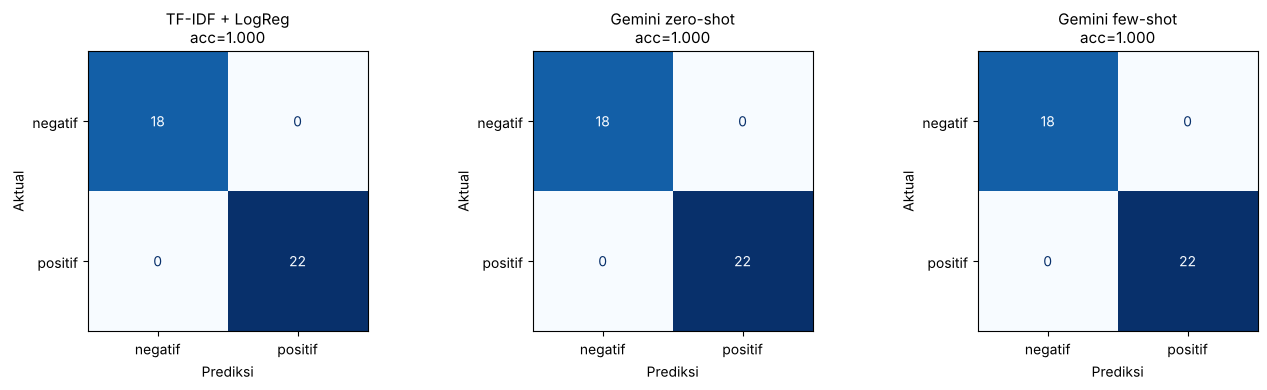

In [19]:
models_to_plot = [("TF-IDF + LogReg", y_pred_classic)] + \
                 [(f"Gemini {m.replace('_','-')}", y_pred_llm_modes[m]) for m in y_pred_llm_modes]
fig, axes = plt.subplots(1, len(models_to_plot), figsize=(4.5 * len(models_to_plot), 4))
axes = np.atleast_1d(axes)
for ax, (name, pred) in zip(axes, models_to_plot):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred, labels=LABELS), display_labels=LABELS) \
        .plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{name}\nacc={accuracy_score(y_test, pred):.3f}", fontsize=11)
    ax.set_xlabel("Prediksi"); ax.set_ylabel("Aktual")
plt.tight_layout(); plt.show()

Pada test set utama, ketiga pendekatan sama-sama sempurna sehingga confusion matrix-nya identik. Perbedaan baru terlihat pada evaluasi leakage-free (Section 6.4) dan uji ketahanan (Section 6.5). Grafik ringkasan semua skenario disimpan di akhir Section 6.5.

### 6.4 Eksperimen Pelengkap: Evaluasi *Leakage-free*

Untuk mengukur generalisasi yang sebenarnya, dipakai split leakage-free dari Section 3.2: kalimat di test set dijamin tidak pernah dilihat saat training. Karena teks unik hanya 40, satu split sangat kecil dan rawan bias, sehingga ditambah **5-fold `GroupKFold` cross-validation** agar estimasi lebih stabil.

LLM juga dievaluasi pada test set leakage-free yang sama (memakai cache bila teksnya sudah pernah diproses).

In [20]:
print(f"Leakage-free split -> train {len(Xg_tr)} baris, test {len(Xg_te)} baris ({Xg_te.nunique()} teks unik)\n")
pipe = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True),
                     LogisticRegression(max_iter=1000, random_state=SEED))
pipe.fit(Xg_tr, yg_tr)
yg_pred_classic = pipe.predict(Xg_te)
res_g_classic = evaluate("[Leakage-free] TF-IDF + LogReg", yg_te, yg_pred_classic)

res_g_llm = {}
if LLM_AVAILABLE:
    for mode in MODES:
        p = {t: classify_sentiment_llm(t, mode) for t in Xg_te.unique()}
        print()
        res_g_llm[mode] = evaluate(f"[Leakage-free] Gemini {mode.replace('_','-')}", yg_te, [p[t] for t in Xg_te])

Leakage-free split -> train 159 baris, test 41 baris (8 teks unik)

=== [Leakage-free] TF-IDF + LogReg ===
Accuracy: 0.6341

              precision    recall  f1-score   support

     negatif     0.4828    1.0000    0.6512        14
     positif     1.0000    0.4444    0.6154        27

    accuracy                         0.6341        41
   macro avg     0.7414    0.7222    0.6333        41
weighted avg     0.8234    0.6341    0.6276        41

Confusion Matrix (baris = aktual, kolom = prediksi):
                pred_negatif  pred_positif
aktual_negatif            14             0
aktual_positif            15            12

=== [Leakage-free] Gemini zero-shot ===
Accuracy: 1.0000

              precision    recall  f1-score   support

     negatif     1.0000    1.0000    1.0000        14
     positif     1.0000    1.0000    1.0000        27

    accuracy                         1.0000        41
   macro avg     1.0000    1.0000    1.0000        41
weighted avg     1.0000    1.0000  

In [21]:
# 5-fold GroupKFold CV untuk model klasik (tiap fold: teks test tidak pernah dilihat saat training)
cv = cross_validate(pipe, X, y, groups=X, cv=GroupKFold(n_splits=5),
                    scoring=["accuracy", "precision_macro", "recall_macro", "f1_macro"])
cv_df = pd.DataFrame({k.replace("test_", ""): v for k, v in cv.items() if k.startswith("test_")})
cv_df.index = [f"fold {i+1}" for i in range(len(cv_df))]
cv_df.loc["mean"] = cv_df.mean()
cv_df.loc["std"] = cv_df.iloc[:5].std()
print("TF-IDF + LogReg, 5-fold GroupKFold (leakage-free):")
cv_df.round(3)

TF-IDF + LogReg, 5-fold GroupKFold (leakage-free):


,accuracy,precision_macro,recall_macro,f1_macro
fold 1,0.475,0.611,0.691,0.458
fold 2,0.775,0.812,0.820,0.775
fold 3,0.600,0.680,0.742,0.591
fold 4,0.400,0.473,0.476,0.398
fold 5,0.450,0.703,0.560,0.396
mean,0.540,0.656,0.658,0.524
std,0.151,0.125,0.139,0.161


In [22]:
lf_rows = [res_g_classic] + [res_g_llm[m] for m in res_g_llm]
lf_summary = pd.DataFrame(lf_rows).set_index("Pendekatan")[["Accuracy", "Precision (macro)", "Recall (macro)", "F1 (macro)", "Recall negatif"]]
lf_summary.loc["[Leakage-free] TF-IDF + LogReg, GroupKFold mean (5-fold)"] = [
    cv_df.loc["mean", "accuracy"], cv_df.loc["mean", "precision_macro"],
    cv_df.loc["mean", "recall_macro"], cv_df.loc["mean", "f1_macro"], np.nan]
lf_summary.round(4).to_csv(RESULTS_DIR / "model_comparison_leakage_free.csv")
lf_summary.round(4)

,Accuracy,Precision (macro),Recall (macro),F1 (macro),Recall negatif
Pendekatan,,,,,
[Leakage-free] TF-IDF + LogReg,0.6341,0.7414,0.7222,0.6333,1.0
[Leakage-free] Gemini zero-shot,1.0000,1.0000,1.0000,1.0000,1.0
[Leakage-free] Gemini few-shot,1.0000,1.0000,1.0000,1.0000,1.0
"[Leakage-free] TF-IDF + LogReg, GroupKFold mean (5-fold)",0.5400,0.6559,0.6578,0.5236,NaN


**Interpretasi:** Begitu diuji pada kalimat yang **belum pernah dilihat**, perbedaan kedua pendekatan menjadi sangat jelas:

- **Model klasik runtuh**: accuracy turun dari 1.00 ke **0.63** (GroupShuffleSplit) dan rata-rata **0.54 ± 0.15** pada 5-fold GroupKFold, hampir setara menebak (baseline 0.55). Pada split leakage-free, recall `negatif` memang 1.00, tetapi precision `negatif` hanya 0.48: 15 dari 27 ulasan positif salah ditandai negatif. Model cenderung "menuduh" negatif setiap kali bertemu kata yang tidak dikenalnya. Standar deviasi antar-fold yang besar (0.15) menunjukkan data latih (32 kalimat unik) terlalu sedikit untuk belajar pola yang stabil.
- **Gemini tetap 1.00** di semua metrik (41/41 baris benar), baik zero-shot maupun few-shot, karena kemampuannya berasal dari pra-pelatihan bahasa, bukan dari hafalan dataset ini.

Catatan kehati-hatian: test set leakage-free hanya berisi 8 kalimat unik, sehingga angka 1.00 Gemini punya ketidakpastian lebar. Namun arah temuannya konsisten dengan uji ketahanan di bawah.

### 6.5 Uji Ketahanan (Robustness Probe)

Dataset ini relatif "bersih": kalimatnya eksplisit dan tidak ambigu. Ulasan nyata sering mengandung negasi, sarkasme, slang, typo, atau sentimen campuran. Berikut 8 ulasan buatan (di luar dataset, label ditentukan manual) untuk **mengamati pola kesalahan** kedua pendekatan. Hasil ini bersifat ilustratif (n kecil) dan **tidak** dimasukkan ke metrik resmi.

In [23]:
probe = pd.DataFrame([
    ("Tidak mengecewakan sama sekali, bakal repeat order.", "positif", "negasi"),
    ("Gak nyesel beli di sini, recommended bgt", "positif", "slang + negasi"),
    ("Wah hebat, baru sehari dipakai udah rusak. Mantap.", "negatif", "sarkasme"),
    ("Barangnya bagus sih, tapi pengirimannya lama banget dan kurirnya kasar.", "negatif", "campuran"),
    ("Kirain bakal jelek, ternyata kualitasnya bagus banget.", "positif", "ekspektasi terbalik"),
    ("brg gk sesuai pesanan, admin jg slow resp", "negatif", "singkatan/typo"),
    ("Murah tapi bukan murahan, puas!", "positif", "kontras"),
    ("Not recommended, quality is very poor.", "negatif", "bahasa Inggris"),
], columns=[TEXT_COL, "label_manual", "tantangan"])

probe["pred_klasik"] = clf.predict(vectorizer.transform(probe[TEXT_COL]))
probe["proba_positif_klasik"] = clf.predict_proba(vectorizer.transform(probe[TEXT_COL]))[:, 1].round(2)
if LLM_AVAILABLE:
    probe["pred_gemini_few_shot"] = [classify_sentiment_llm(t, "few_shot") for t in probe[TEXT_COL]]

for c in [c for c in probe.columns if c.startswith("pred_")]:
    print(f"{c}: benar {(probe[c] == probe['label_manual']).sum()}/{len(probe)}")
probe.to_csv(RESULTS_DIR / "robustness_probe.csv", index=False)
probe

pred_klasik: benar 4/8
pred_gemini_few_shot: benar 8/8


,review_text,label_manual,tantangan,pred_klasik,proba_positif_klasik,pred_gemini_few_shot
0,"Tidak mengecewakan sama sekali, bakal repeat order.",positif,negasi,positif,0.54,positif
1,"Gak nyesel beli di sini, recommended bgt",positif,slang + negasi,positif,0.65,positif
2,"Wah hebat, baru sehari dipakai udah rusak. Mantap.",negatif,sarkasme,negatif,0.45,negatif
3,"Barangnya bagus sih, tapi pengirimannya lama banget dan kurirnya kasar.",negatif,campuran,positif,0.67,negatif
4,"Kirain bakal jelek, ternyata kualitasnya bagus banget.",positif,ekspektasi terbalik,positif,0.61,positif
5,"brg gk sesuai pesanan, admin jg slow resp",negatif,singkatan/typo,positif,0.53,negatif
6,"Murah tapi bukan murahan, puas!",positif,kontras,negatif,0.48,positif
7,"Not recommended, quality is very poor.",negatif,bahasa Inggris,positif,0.67,negatif


**Pengamatan:** Gemini few-shot benar **8/8**, sedangkan model klasik hanya **4/8**. Bahkan yang benar pun diprediksi model klasik dengan probabilitas 0.45–0.65, tidak jauh dari menebak.

| Kasus | Model klasik | Gemini | Penjelasan |
|---|---|---|---|
| Campuran ("bagus sih, tapi... lama banget dan kurirnya kasar") | salah (positif) | benar (negatif) | Klasik terbawa kata "bagus"; LLM menangkap bahwa keluhan mendominasi |
| Singkatan/typo ("brg gk sesuai, admin jg slow resp") | salah (positif) | benar (negatif) | Kata "brg", "gk", "slow resp" tidak ada di vocabulary TF-IDF |
| Kontras ("Murah tapi bukan murahan, puas!") | salah (negatif) | benar (positif) | Kata "murahan" berbobot negatif di data latih |
| Bahasa Inggris ("Not recommended...") | salah (positif) | benar (negatif) | "recommended" berbobot positif; "not" tidak dikenal |

Ini menunjukkan keterbatasan utama model klasik: ia hanya mengenali **kata** yang pernah dilihat, bukan **makna** kalimat.

#### Grafik ringkasan semua skenario evaluasi

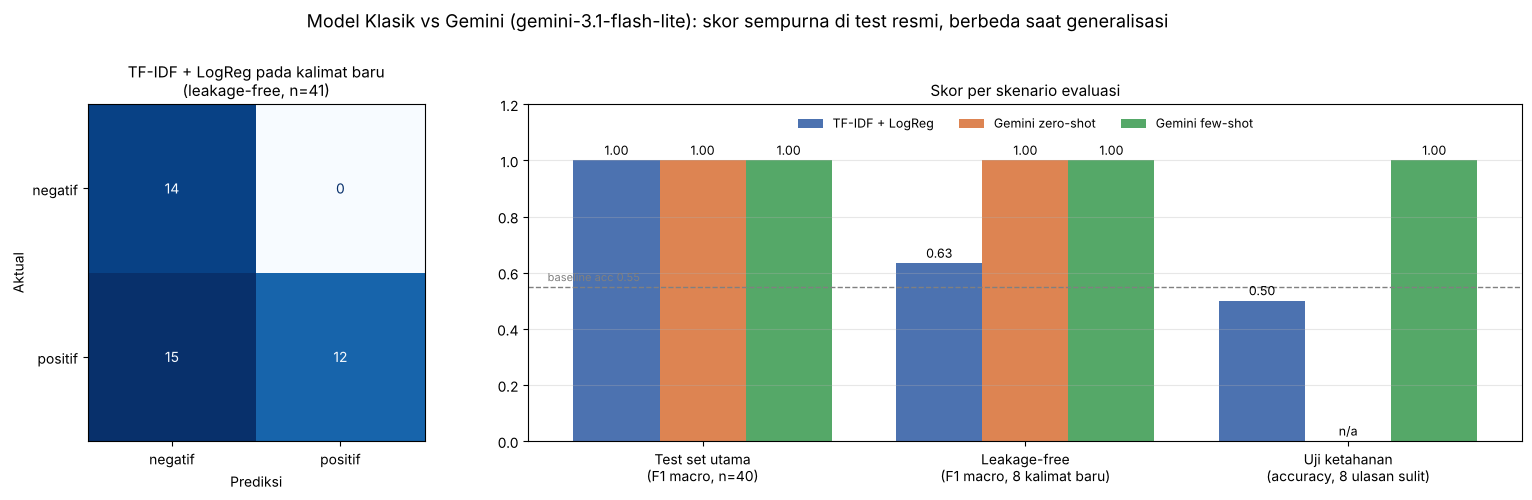

In [24]:
names = ["TF-IDF + LogReg"] + [f"Gemini {m.replace('_','-')}" for m in res_llm]
scen = {
    "Test set utama\n(F1 macro, n=40)": [res_classic["F1 (macro)"]] + [res_llm[m]["F1 (macro)"] for m in res_llm],
    "Leakage-free\n(F1 macro, 8 kalimat baru)": [res_g_classic["F1 (macro)"]] + [res_g_llm[m]["F1 (macro)"] for m in res_g_llm],
    "Uji ketahanan\n(accuracy, 8 ulasan sulit)": [(probe["pred_klasik"] == probe["label_manual"]).mean()]
        + [((probe["pred_gemini_few_shot"] == probe["label_manual"]).mean() if m == "few_shot" and "pred_gemini_few_shot" in probe else np.nan) for m in res_llm],
}
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1, 2.2]})
# Panel kiri: confusion matrix model klasik pada split leakage-free (sumber kesalahan utama)
ConfusionMatrixDisplay(confusion_matrix(yg_te, yg_pred_classic, labels=LABELS), display_labels=LABELS) \
    .plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("TF-IDF + LogReg pada kalimat baru\n(leakage-free, n=41)", fontsize=11)
axes[0].set_xlabel("Prediksi"); axes[0].set_ylabel("Aktual")
# Panel kanan: skor per skenario
x = np.arange(len(scen)); w = 0.8 / len(names)
colors = ["#4C72B0", "#DD8452", "#55A868"]
for i, n in enumerate(names):
    vals = [scen[k][i] for k in scen]
    bars = axes[1].bar(x + (i - (len(names) - 1) / 2) * w, np.nan_to_num(vals), w, label=n, color=colors[i % 3])
    for b, v in zip(bars, vals):
        axes[1].text(b.get_x() + b.get_width() / 2, (0 if np.isnan(v) else v) + 0.02,
                     "n/a" if np.isnan(v) else f"{v:.2f}", ha="center", fontsize=9)
axes[1].axhline(res_baseline["Accuracy"], ls="--", c="gray", lw=1)
axes[1].text(-0.48, res_baseline["Accuracy"] + 0.02, "baseline acc 0.55", fontsize=8, color="gray", ha="left")
axes[1].set_xticks(x); axes[1].set_xticklabels(list(scen), fontsize=10)
axes[1].set_ylim(0, 1.2); axes[1].legend(loc="upper center", ncol=3, frameon=False, fontsize=9)
axes[1].set_title("Skor per skenario evaluasi", fontsize=11); axes[1].grid(axis="y", alpha=0.3)
plt.suptitle(f"Model Klasik vs Gemini ({GEMINI_MODEL}): skor sempurna di test resmi, berbeda saat generalisasi",
             fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig(DOCS_DIR / "model_comparison_summary.png", dpi=150, bbox_inches="tight")
plt.show()

### 6.6 Kecepatan & Estimasi Biaya

In [25]:
# Harga publik Gemini API (paid tier, per 1 juta token), sumber: ai.google.dev/gemini-api/docs/pricing (diakses Okt 2026).
# Output price sudah termasuk thinking tokens. Harga dapat berubah, cek kembali sebelum dipakai untuk keputusan.
PRICE_PER_1M = {
    "gemini-3.8-flash": (0.75, 3.75), "gemini-3.6-flash": (0.75, 3.75),
    "gemini-3.5-flash-lite": (0.30, 2.50), "gemini-3.1-flash-lite": (0.25, 1.50),
}
USD_TO_IDR = 16_500  # asumsi kurs

print(f"Model klasik : training {train_time*1000:.1f} ms, inferensi {classic_infer_time/len(X_test)*1000:.3f} ms/ulasan, "
      f"biaya API = Rp0 (jalan di CPU lokal)\n")

cost_rows = []
for m, c in llm_cost.items():
    if not c["calls"]:
        continue
    p_in, p_out = PRICE_PER_1M.get(GEMINI_MODEL, (np.nan, np.nan))
    cost = c["input_tokens"] / 1e6 * p_in + c["output_tokens"] / 1e6 * p_out
    per_review = cost / c["calls"]
    cost_rows.append({
        "Strategi": m, "Panggilan API": c["calls"],
        "Token input/ulasan": round(c["input_tokens"] / c["calls"], 1),
        "Token output+thinking/ulasan": round(c["output_tokens"] / c["calls"], 1),
        "Latensi median (s)": round(c["median_latency_s"], 2) if c["median_latency_s"] else None,
        "Latensi rata-rata (s)": round(c["mean_latency_s"], 2) if c["mean_latency_s"] else None,
        "Latensi p95 (s)": round(c["p95_latency_s"], 2) if c["p95_latency_s"] else None,
        "Biaya eksperimen (USD)": round(cost, 6),
        "Proyeksi 1 juta ulasan (USD)": round(per_review * 1e6, 2),
        "Proyeksi 1 juta ulasan (IDR)": f"{per_review * 1e6 * USD_TO_IDR:,.0f}",
    })
cost_df = pd.DataFrame(cost_rows)
cost_df.to_csv(RESULTS_DIR / "llm_cost_latency.csv", index=False)
cost_df

Model klasik : training 8.1 ms, inferensi 0.025 ms/ulasan, biaya API = Rp0 (jalan di CPU lokal)



,Strategi,Panggilan API,Token input/ulasan,Token output+thinking/ulasan,Latensi median (s),Latensi rata-rata (s),Latensi p95 (s),Biaya eksperimen (USD),Proyeksi 1 juta ulasan (USD),Proyeksi 1 juta ulasan (IDR)
0,zero_shot,26,139.6,112.1,6.48,11.46,22.01,0.005278,203.01,"3,349,659"
1,few_shot,26,245.6,109.9,7.64,27.13,93.42,0.005882,226.22,"3,732,649"


In [26]:
# Simpan ringkasan metrik ke JSON (dipakai untuk dokumentasi README)
out = {
    "model_gemini": GEMINI_MODEL, "temperature": TEMPERATURE,
    "split_utama": {"train": len(X_train), "test": len(X_test), "test_leaked_rows": int(leaked.sum())},
    "main": summary.round(4).reset_index().to_dict(orient="records"),
    "leakage_free": lf_summary.round(4).reset_index().to_dict(orient="records"),
    "classic_timing_ms": {"train": train_time * 1000, "infer_per_review": classic_infer_time / len(X_test) * 1000},
    "llm_cost_latency": cost_rows,
}
(RESULTS_DIR / "metrics_summary.json").write_text(json.dumps(out, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
print("Tersimpan:", sorted(p.name for p in RESULTS_DIR.iterdir()))

Tersimpan: ['llm_cache.json', 'llm_cost_latency.csv', 'metrics_summary.json', 'model_comparison.csv', 'model_comparison_leakage_free.csv', 'predictions_test_set.csv', 'robustness_probe.csv', 'test_set.csv']


## 7. Analisis Trade-off dan Limitation

### 7.1 Performa (metrik evaluasi)

| Skenario evaluasi | TF-IDF + LogReg | Gemini zero-shot | Gemini few-shot |
|---|---|---|---|
| Test set utama (n=40, 98% kalimat bocor dari train) | F1 1.00 | F1 1.00 | F1 1.00 |
| Leakage-free GroupShuffleSplit (n=41, 8 kalimat baru) | F1 0.63 | **F1 1.00** | **F1 1.00** |
| Leakage-free 5-fold GroupKFold | F1 0.52 ± 0.16 | - | - |
| Uji ketahanan (8 ulasan sulit) | 4/8 | - | **8/8** |

Pada test set resmi, **keduanya seri sempurna**, tetapi seri ini menyesatkan. Begitu leakage dihilangkan, **Gemini jelas lebih unggul** dalam generalisasi ke ulasan baru, yaitu kondisi nyata di produksi, di mana hampir setiap ulasan baru berbeda dari data latih.

### 7.2 Effort implementasi, kecepatan, dan biaya

| Aspek | Model klasik | Gemini (LLM API) |
|---|---|---|
| **Effort awal** | Butuh dataset berlabel yang besar & beragam, lalu training, tuning, dan retraining berkala. Dataset ini (40 kalimat unik) jelas tidak cukup. | Tanpa training. Cukup merancang prompt (±1 jam), langsung bisa dipakai. |
| **Effort operasional** | Rendah: model kecil (384 fitur), jalan offline di CPU. | Tinggi: perlu API key, retry/backoff, caching, monitoring kuota, dan antisipasi pergantian model. |
| **Latensi** | **±0,02–0,05 ms/ulasan** (lokal) | **Median 6,5–7,6 s/ulasan**, p95 22–93 s. Selama eksperimen server sedang padat (banyak error 503), jadi angka ini lebih buruk dari kondisi normal, tapi tetap ratusan ribu kali lebih lambat dari model klasik. |
| **Biaya** | ≈ Rp0 (hanya biaya server) | ±US$0,0002/ulasan → **±US$203 (≈ Rp3,3 juta) per 1 juta ulasan** (zero-shot). Few-shot ±11% lebih mahal tanpa peningkatan akurasi. |
| **Ketersediaan** | Selalu tersedia | Bergantung pada pihak ketiga (lihat 7.3) |

Temuan biaya penting: dari ±112 token output per ulasan, **±110 adalah thinking token**, sedangkan jawabannya hanya 2 token. Artinya ±83% biaya habis untuk "berpikir" pada tugas sederhana. Menurunkan `thinking_level` ke `MINIMAL` berpotensi memangkas biaya dan latensi secara signifikan (perlu divalidasi ulang akurasinya).

### 7.3 Limitation yang ditemukan

**Model klasik (TF-IDF + Logistic Regression)**
- **Menghafal, bukan memahami.** Skor 1.00 pada split resmi adalah artefak leakage. Pada kalimat baru, akurasinya ≈ menebak (0.54).
- **Vocabulary tertutup.** Gagal pada typo/singkatan ("brg gk"), bahasa Inggris, dan kalimat kontras ("murah tapi bukan murahan"), karena kata-kata itu tidak ada di 384 fitur.
- **Bias kata permukaan.** Kata "bagus" membuat ulasan campuran dianggap positif, dan kata "murahan" membuat pujian dianggap negatif.
- **Butuh data jauh lebih banyak.** Dengan 32–40 kalimat unik, variansi antar-fold mencapai ±0.15.

**LLM API (Gemini)**
- **Rentan gangguan layanan eksternal.** Ini terjadi langsung saat eksperimen: kuota harian free tier `gemini-3.8-flash` habis setelah ±15 panggilan (429), project sempat diblokir (403), `gemini-2.5-flash` tidak bisa diakses project baru (404), dan server padat (503). Model `gemini-2.0-flash` dari starter notebook bahkan sudah dihentikan Google. Eksperimen akhirnya memakai `gemini-3.1-flash-lite`.
- **Latensi tinggi dan tidak stabil** (median ±7 s, kasus terburuk >90 s). Tidak cocok untuk klasifikasi sinkron saat halaman dimuat.
- **Biaya berbanding lurus dengan volume**, dan tidak ada biaya nol.
- **Privasi data.** Teks ulasan dikirim ke pihak ketiga, yang perlu dicek terhadap kebijakan data perusahaan.
- **Evaluasi masih terbatas.** Dataset ini berisi kalimat yang eksplisit dan tidak ambigu. Skor 1.00 belum menjamin performa yang sama pada ulasan nyata yang lebih panjang, ambigu, atau bersentimen netral. Kesalahan prediksi Gemini belum teramati di eksperimen ini, sehingga pola kegagalannya belum diketahui.

## 8. Rekomendasi Technical Approach

**Rekomendasi: kembangkan LLM API (Gemini, zero-shot) sebagai pendekatan utama**, dengan arsitektur asinkron + caching, lalu siapkan jalur menuju model sendiri.

**Alasan memilih LLM API:**
1. **Satu-satunya pendekatan yang terbukti generalisasi.** Pada kalimat yang belum pernah dilihat, Gemini mencapai F1 1.00 sementara model klasik hanya 0.52–0.63. Di produksi hampir semua ulasan adalah kalimat baru, jadi skor leakage-free inilah yang relevan, bukan skor 1.00 di split resmi.
2. **Tahan terhadap bahasa ulasan nyata.** Gemini benar pada typo, singkatan, sarkasme, kalimat campuran, dan bahasa Inggris (8/8), di mana model klasik gagal separuhnya.
3. **Tidak butuh dataset berlabel besar.** Dataset yang tersedia (40 kalimat unik) tidak cukup untuk melatih model klasik yang andal. LLM bisa langsung dipakai.
4. **Zero-shot sudah cukup.** Few-shot tidak menambah akurasi tetapi menambah ±76% token input, jadi pilih zero-shot.

**Cara mengatasi kelemahan LLM (berdasarkan temuan eksperimen):**
- **Proses asinkron, bukan real-time.** Klasifikasikan ulasan saat ulasan dikirim (lewat background job/queue), lalu simpan labelnya di database. Halaman produk cukup membaca label tersimpan, sehingga latensi 7 detik tidak terasa oleh pengguna.
- **Caching per teks.** Di dataset ini 80% ulasan adalah duplikat. Dengan `temperature=0`, ulasan identik cukup diklasifikasikan sekali (pola ini sudah diterapkan di notebook).
- **Pakai paid tier + retry/backoff + fallback model** untuk menghindari kuota free tier dan error 503. Pantau pengumuman deprecation model.
- **Turunkan `thinking_level` ke `MINIMAL`** dan validasi ulang, karena ±83% biaya saat ini adalah thinking token.
- **Fallback saat API gagal:** tandai ulasan sebagai "belum diklasifikasi" dan proses ulang, jangan menebak.

**Jangka menengah: hybrid / distilasi.** Gunakan label hasil Gemini (ditambah validasi manual pada sampel) untuk membangun dataset berlabel ribuan ulasan nyata. Setelah datanya cukup, latih model sendiri (TF-IDF+LogReg atau fine-tune IndoBERT) dan evaluasi dengan **split leakage-free**. Jika performanya setara, model sendiri bisa mengambil alih traffic volume tinggi dengan biaya ≈ Rp0 dan latensi milidetik, sementara LLM dipakai untuk kasus yang confidence-nya rendah.

**Kapan rekomendasi ini berubah:** model klasik layak dipilih jika (a) tersedia dataset berlabel besar dan beragam, (b) volume sangat tinggi sehingga biaya API tidak masuk akal, (c) klasifikasi harus real-time di bawah 100 ms, atau (d) kebijakan privasi melarang data dikirim ke pihak ketiga.